### *Algoritmos Genéticos y Optimización Heurística - UTN-FRT*

# **Trabajo Práctico N°1**
### Tema: Hill Climbing

***Integrantes***

*   Breslauer, León - 56340
*   Perez, Francisco - 56355



## Ejercicio 1
El siguiente código es una implementación simple del algoritmo Hill Climbing, al cual le faltan algunas líneas para funcionar correctamente. Su trabajo consiste en completar el código y probar el algoritmo con una función de prueba (Benchmark).

In [1]:
# Importar funciones declaradas en el archivo helper.
from helper_hill_climbing import validate_inputs, graficarCaminata, graficarEvolucionFitness

La siguiente función calcula un nuevo punto de exploración a partir de un vector solución dado. La función es utilizada en el método de Hill Climbing.

In [2]:
def puntoExploracion(X0, max_eps):
    """Calcular un nuevo punto de exploración o solución, a partir de
    una solución previa.

    Parameters
    ----------
    X0: list
        Vector solucion inicial.
    max_eps: float
        Valor del tamaño máximo del paso.

    Returns
    -------
    X : list
        Vector solución generado.
    R : list
        Vector dirección.
    """

    # Formación de vector de avance R
    R = [2 * random.random() - 1 for _ in X0]
    norm = math.sqrt(sum([r_i**2 for r_i in R]))

    # Normalización del vector de avance para que sea unitario
    R = [r_i / norm for r_i in R] if norm > 0 else R

    # Generación de paso aleatorio y formación de nuevo punto de solución X
    eps = random.random() * max_eps
    X = [x0_i + eps * r_i for x0_i, r_i in zip(X0, R)]

    return X, R

In [3]:
import random
import math

def HillClimbing(fitness, X_mejor, max_eps, bounds, cant_iterac):
    """Algoritmo de Hill Climbing.

    Parameters:
    -----------
    fitness : function
        Funcion de evaluacion a optimizar
    X_mejor: list
        Vector solucion inicial, desde donde parte la exploracion.
    max_eps: float
        Valor de distancia maxima del paso a recorrer en cada iteracion.
    bounds: list(tuple)
        Matriz de tamano nx2, donde n es la cantidad de variables que
        tiene el problema (cantidad de coordenadas del vector solución).
        En la primera columna se establecen los valores limites inferiores y
        en la segunda columna se establece los valores limite superiores.
        Observen que los valores de la primera columna siempre deben ser
        menores que los de la segunda).
    cant_iterac: integer
        Cantidad de iteraciones usada como condicion de terminacion.

    Return:
    -------
    X_mejor : list
        Vector solución correspondiente a la mejor solución encontrada.
    fX_mejor : list
        Valor de evaluación de la mejores solución encontrada.
    Trace_R : list
        Lista con los vectores dirección calculados en cada iteración.
    Trace_X : list
        Lista con las soluciones calculadas en cada iteración.
    Trace_X_mejor : list
        Lista con las mejores soluciones de cada iteración.
    Trace_f : list
        Lista con los valores de evaluación de la mejor y peor solución.
    """

    fX_mejor = 0
    Trace_R = []
    Trace_X = []
    Trace_X_mejor = []
    Trace_f = []

    if not validate_inputs(X_mejor, bounds, cant_iterac, max_eps):
        return X_mejor, fX_mejor, Trace_R, Trace_X, Trace_X_mejor, Trace_f

    # evaluacion inicial
    fX_mejor = fitness(X_mejor)

    # inicializar variables
    Trace_R.append([0 for xi in X_mejor])
    Trace_X.append(X_mejor)
    Trace_X_mejor.append(X_mejor)
    Trace_f.append((fX_mejor,fX_mejor))
    it = 0
    cnt = 0
    sigue = True

    # repetir hasta que se cumpla la condicion de terminacion
    while sigue:
        #  calculo el punto de exploracion
        X, R = puntoExploracion(X_mejor, max_eps)

        # verifico y corrijo que X este dentro del dominio
        for i, xi in enumerate(X):
            X[i] = bounds[i][0] if xi < bounds[i][0] else xi
            X[i] = bounds[i][1] if xi > bounds[i][1] else xi

        # evaluo solucion
        fX0 = fX_mejor
        fX = fitness(X)

        # si la solucion actual es mejor que la que ya tenía
        if fX >= fX_mejor:
            X_mejor = X
            fX_mejor = fX
            cnt = 0
        else:
            cnt = cnt + 1

        # condicion de terminacion
        if cnt > cant_iterac:
            sigue = False

        # guardo valores para analisis posterior
        Trace_R.append(R)
        Trace_X.append(X)
        Trace_X_mejor.append(X_mejor)
        Trace_f.append((max(fX, fX0), min(fX, fX0)))

        # incremento el tiempo
        it = it + 1

        # imprimir solo si obtuve una mejor solucion
        if fX >= fX0:
            print("It.{0}: {1} -> {2}".format(it,
                [round(xi,2) for xi in X], round(fX_mejor,4)))

    print(X_mejor, fX_mejor)

    return X_mejor, fX_mejor, Trace_R, Trace_X, Trace_X_mejor, Trace_f

Probar el algoritmo con el siguiente fragmento de código:

It.1: [5] -> -25
It.2: [5] -> -25
It.3: [5] -> -25
It.4: [4.51] -> -20.327
It.7: [4.25] -> -18.096
It.8: [3.99] -> -15.92
It.9: [3.65] -> -13.3219
It.10: [3.32] -> -11.0416
It.11: [3.07] -> -9.4246
It.12: [2.81] -> -7.8735
It.13: [2.67] -> -7.1491
It.15: [2.33] -> -5.4461
It.16: [2.08] -> -4.3386
It.20: [1.97] -> -3.8905
It.21: [1.62] -> -2.6272
It.22: [1.53] -> -2.3376
It.23: [1.37] -> -1.8814
It.24: [1.14] -> -1.2893
It.26: [1.1] -> -1.206
It.27: [1.02] -> -1.045
It.29: [0.96] -> -0.9225
It.31: [0.66] -> -0.4323
It.34: [0.17] -> -0.0296
It.36: [-0.06] -> -0.0042
It.41: [-0.05] -> -0.0024
It.42: [-0.03] -> -0.0012
It.45: [0.02] -> -0.0005
It.52: [-0.02] -> -0.0002
[-0.015588259188632048] -0.00024299382453197148
-----
Solución: [-0.015588259188632048]
Fitness: -0.00024299382453197148
Iteraciones: 73


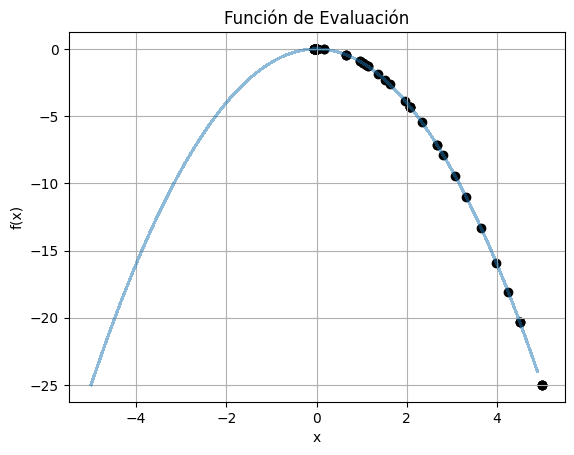

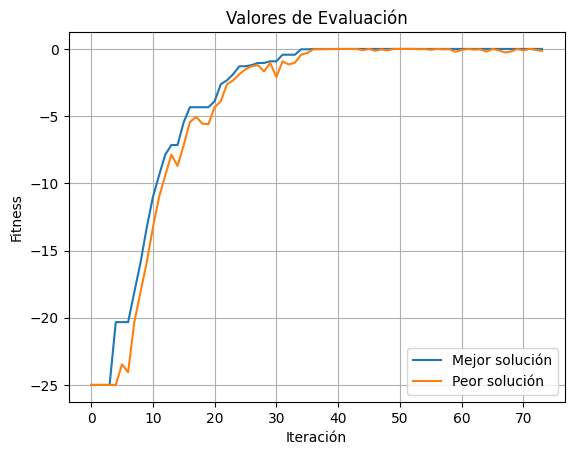

In [4]:
def parabola(x_vars):
    return -sum([x**2 for x in x_vars])

n_variables = 1
bounds = [(-5,5) for i in range(n_variables)]
x0 = [row[1] for row in bounds] # punto inicial en una de las esquinas
max_eps = 0.5
cant_iterac = 20
resolution_grafico = 0.1

X_mejor, fX_mejor, Trace_R, Trace_X, Trace_X_mejor, Trace_f = HillClimbing(
    parabola, x0, max_eps, bounds, cant_iterac)

print("-----")
print("Solución: {0}".format(X_mejor))
print("Fitness: {0}".format(fX_mejor))
print("Iteraciones: {0}".format(len(Trace_X)-1))

graficarCaminata(parabola, Trace_X_mejor, bounds, resolution_grafico)
graficarEvolucionFitness(Trace_f)

## Ejercicio 2
Contestar las siguientes preguntas:
1.    ¿El algoritmo proporcionado está diseñado para buscar el máximo o el mínimo de la función?
2.    Explicar con sus palabras en qué consiste la condición de terminación propuesta.

***Respuestas***
1. El algoritmo está diseñado para buscar el **máximo** de la función. Esto se puede ver en el bucle principal de la función HillClimbing, en la siguiente condición para actualizar la solución:
```
if fX >= fX_mejor:
    X_mejor = X
    fX_mejor = fX
```
- Esto anterior significa que el algoritmo solo acepta y se desplaza hacia un nuevo punto ***X*** si su valor de evaluación es mayor o igual al que ya poseía (`fX >= fX_mejor`).

2. La condición de terminación propuesta consiste en detener la búsqueda tras transcurrir una cantidad N (`cant_iterac`) de **iteraciones consecutivas sin logar ninguna mejora en el fitness**. Para ello, se usa un contador de intentos fallidos (`cnt`), y cada vez que se explora una solución y esta no supera el valor actual (`fX < fX_mejor`), el contador se incrementa en uno (`cnt = cnt + 1`). Si en algún momento se encuentra una solución que mejora o iguala el fitness, el contador se reinicio a cero (`cnt = 0`). Por último, el bucle finaliza cuando el contador supera el umbral fijado (`cnt > cant_iterac`)

## Ejercicio 3

Reutilizando el código anterior, compruebe el funcionamiento del algoritmo buscando un óptimo local en los siguientes casos:
1.   F(x, y) = -x^2 - y^2, x, y ∈ [-5, 5]
2.   g(x)= -0.01 x^2 - cos(2x), x ∈ [-4𝜋, 4𝜋]
3.   G(x, y) = -0.01(x^2+y^2)-cos(2x)-cos(2y), x,y ∈ [-4𝜋, 4𝜋]

En cada caso se pide:
1.   Ajuste adecuadamente los parámetros del algoritmo (tamaño máximo del paso y cantidad de iteraciones), de manera de asegurar que encuentre un óptimo local independientemente de cuál sea el punto inicial, en más del 80% de las ejecuciones. Considere dos cifras decimales de precisión para determinar que llegó al óptimo.
2.    Genere un gráfico con la “caminata” realizada, es decir donde se muestre todos los puntos por donde el algoritmo fue explorando, desde el punto inicial hasta llegar a la solución final.
3.    Generar un gráfico con los valores de fitness de las soluciones encontradas en cada iteración del algoritmo.

It.3: [3.59, 1.83] -> -16.2313
It.6: [3.62, 1.64] -> -15.7747
It.8: [3.54, 1.72] -> -15.4986
It.9: [3.62, 1.55] -> -15.4596
It.11: [3.62, 1.55] -> -15.458
It.12: [3.64, 1.45] -> -15.3792
It.13: [3.55, 1.31] -> -14.3326
It.15: [3.43, 1.38] -> -13.698
It.16: [3.29, 1.44] -> -12.9303
It.17: [3.12, 1.45] -> -11.8506
It.18: [3.05, 1.35] -> -11.1218
It.19: [2.95, 1.4] -> -10.6756
It.21: [2.92, 1.43] -> -10.5629
It.24: [2.81, 1.54] -> -10.2526
It.26: [2.78, 1.43] -> -9.7781
It.28: [2.74, 1.36] -> -9.3594
It.33: [2.62, 1.26] -> -8.4814
It.43: [2.52, 1.23] -> -7.8713
It.44: [2.57, 1.06] -> -7.7405
It.45: [2.48, 1.1] -> -7.3871
It.46: [2.31, 1.06] -> -6.4376
It.52: [2.23, 0.93] -> -5.8421
It.53: [2.27, 0.82] -> -5.8279
It.56: [2.27, 0.81] -> -5.8045
It.58: [2.25, 0.83] -> -5.7601
It.59: [2.17, 0.89] -> -5.5135
It.60: [2.03, 0.91] -> -4.9656
It.62: [1.94, 0.94] -> -4.6738
It.64: [1.91, 0.94] -> -4.5443
It.65: [1.84, 0.9] -> -4.177
It.66: [1.84, 0.89] -> -4.1544
It.67: [1.74, 0.99] -> -4.0035
It.6

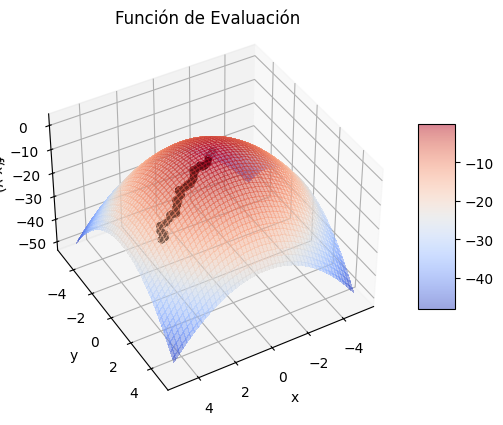

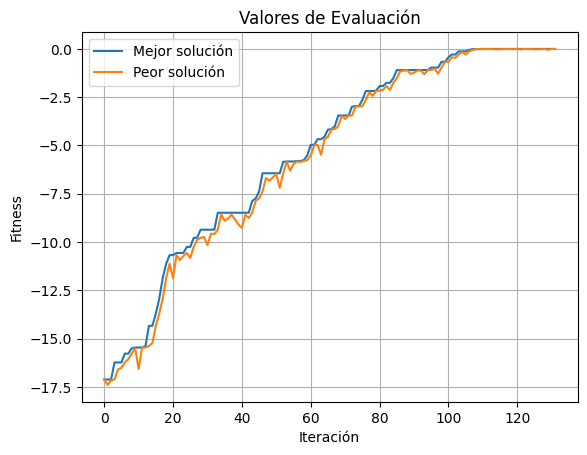

In [ ]:
import math
def f(X_vars):
    return -sum( [xi**2 for xi in X_vars] )

bounds_F = [(-5,5), (-5,5)]

# Punto inicial aleatorio
x0_F = [random.uniform(b[0], b[1]) for b in bounds_F]

max_eps_F = 0.2
cant_iterac_F = 20
resolution_grafico_F = 0.1

X_mejor_F, fX_mejor_F, Trace_R_F, Trace_X_F, Trace_X_mejor_F, Trace_f_F = HillClimbing(
    f, x0_F, max_eps_F, bounds_F, cant_iterac_F)

print(f"Punto inicial: {[round(x, 2) for x in x0_F]}")
print(f"Solución final: {[round(x, 2) for x in X_mejor_F]}")
print(f"Fitness alcanzado: {round(fX_mejor_F, 4)}")
print(f"Iteraciones totales: {len(Trace_X_F) - 1}")

# Gráficos
graficarCaminata(f, Trace_X_mejor_F, bounds_F, resolution_grafico_F)
graficarEvolucionFitness(Trace_f_F)

It.2: [-9.01] -> -1.4905
It.3: [-9.0] -> -1.4672
It.4: [-8.98] -> -1.4401
It.6: [-8.97] -> -1.4164
It.7: [-8.95] -> -1.3855
It.8: [-8.92] -> -1.3201
It.9: [-8.88] -> -1.2555
It.10: [-8.88] -> -1.2553
It.11: [-8.87] -> -1.2346
It.12: [-8.83] -> -1.154
It.13: [-8.81] -> -1.1055
It.16: [-8.77] -> -1.0297
It.18: [-8.73] -> -0.9493
It.19: [-8.71] -> -0.9053
It.20: [-8.68] -> -0.832
It.21: [-8.68] -> -0.8308
It.24: [-8.66] -> -0.8005
It.27: [-8.66] -> -0.7928
It.28: [-8.61] -> -0.6867
It.30: [-8.59] -> -0.6453
It.32: [-8.56] -> -0.5643
It.33: [-8.54] -> -0.5284
It.34: [-8.53] -> -0.5032
It.37: [-8.51] -> -0.4705
It.39: [-8.51] -> -0.458
It.40: [-8.5] -> -0.4519
It.41: [-8.47] -> -0.3775
It.42: [-8.42] -> -0.289
It.43: [-8.42] -> -0.2817
It.45: [-8.41] -> -0.2691
It.49: [-8.4] -> -0.2415
It.53: [-8.38] -> -0.2097
It.54: [-8.38] -> -0.2083
It.55: [-8.36] -> -0.1627
It.61: [-8.31] -> -0.076
It.62: [-8.26] -> 0.0077
It.64: [-8.25] -> 0.0213
It.65: [-8.24] -> 0.0372
It.66: [-8.19] -> 0.1104
It.67

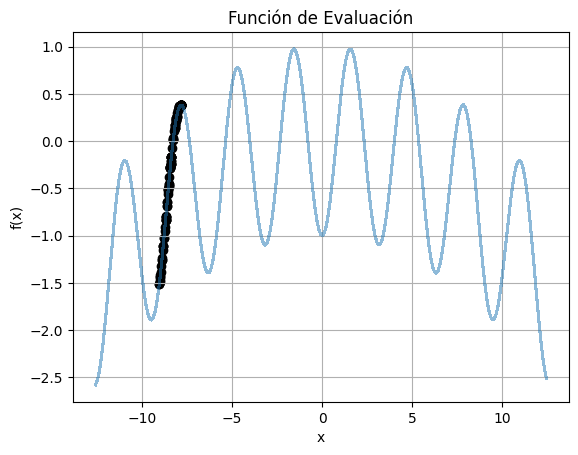

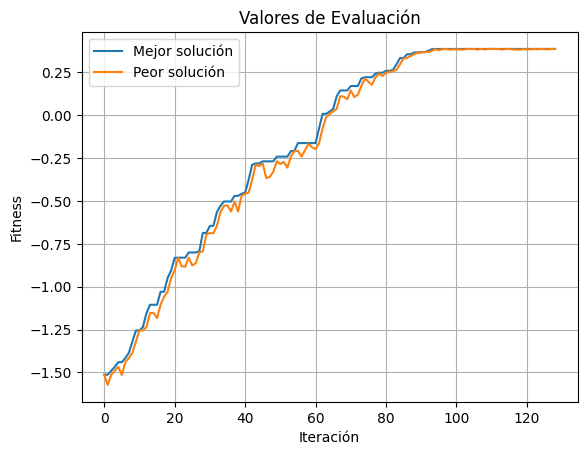

In [ ]:
import math
def g(X_vars):
    return -0.01 * sum([xi**2 for xi in X_vars]) - sum([math.cos(2*xi) for xi in X_vars])

bounds_g = [(-4 * math.pi, 4 * math.pi)]

# Punto inicial aleatorio
x0_g = [random.uniform(bounds_g[0][0], bounds_g[0][1])]

max_eps_g = 0.05
cant_iterac_g = 30
resolution_grafico = 0.1

X_mejor_g, fX_mejor_g, Trace_R_g, Trace_X_g, Trace_X_mejor_g, Trace_f_g = HillClimbing(
    g, x0_g, max_eps_g, bounds_g, cant_iterac_g
)

print(f"Punto inicial: {[round(x, 2) for x in x0_g]}")
print(f"Solución final: {[round(x, 2) for x in X_mejor_g]}")
print(f"Fitness alcanzado: {round(fX_mejor_g, 4)}")
print(f"Iteraciones totales: {len(Trace_X_g) - 1}")

# Gráficos
graficarCaminata(g, Trace_X_mejor_g, bounds_g, resolution_grafico)
graficarEvolucionFitness(Trace_f_g)

It.2: [9.06, -0.48] -> -2.1448
It.5: [9.06, -0.49] -> -2.1347
It.7: [9.07, -0.49] -> -2.1308
It.13: [9.03, -0.54] -> -2.0023
It.14: [9.0, -0.6] -> -1.827
It.15: [8.98, -0.6] -> -1.8067
It.18: [8.99, -0.61] -> -1.7972
It.20: [8.96, -0.66] -> -1.6666
It.23: [8.93, -0.63] -> -1.6584
It.24: [8.93, -0.63] -> -1.6574
It.26: [8.95, -0.68] -> -1.5968
It.27: [8.95, -0.68] -> -1.5947
It.28: [8.97, -0.72] -> -1.5647
It.30: [9.02, -0.76] -> -1.5515
It.33: [8.98, -0.78] -> -1.4493
It.35: [8.96, -0.83] -> -1.306
It.37: [8.91, -0.88] -> -1.1301
It.45: [8.86, -0.94] -> -0.9272
It.46: [8.89, -1.0] -> -0.8688
It.47: [8.86, -1.05] -> -0.7098
It.51: [8.84, -1.11] -> -0.5756
It.52: [8.77, -1.1] -> -0.4546
It.57: [8.76, -1.09] -> -0.4354
It.58: [8.76, -1.15] -> -0.3515
It.60: [8.76, -1.15] -> -0.3449
It.62: [8.72, -1.21] -> -0.1739
It.71: [8.65, -1.2] -> -0.0506
It.72: [8.6, -1.16] -> 0.0081
It.73: [8.57, -1.22] -> 0.1476
It.75: [8.52, -1.2] -> 0.241
It.76: [8.51, -1.25] -> 0.3168
It.77: [8.51, -1.29] -> 0.

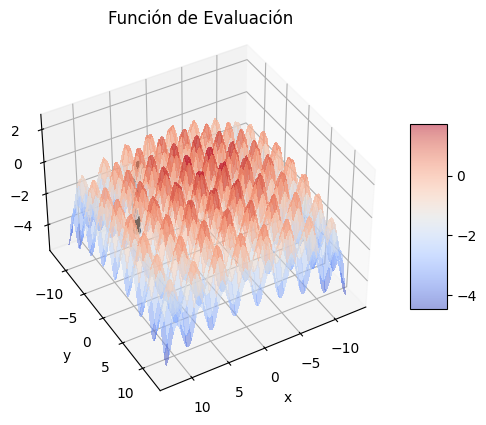

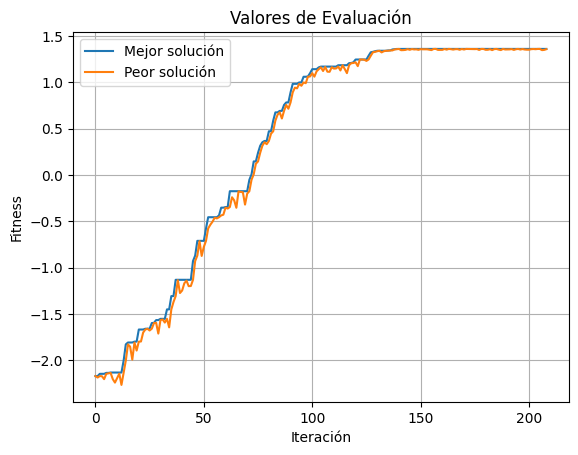

In [ ]:
import math

def G(X_vars):
    return -0.01 * sum([xi**2 for xi in X_vars]) - sum([math.cos(2*xi) for xi in X_vars])

bounds_G = [(-4*math.pi, 4*math.pi) for i in range (2)]

# Punto inicial aleatorio
x0_G = [random.uniform(b[0], b[1]) for b in bounds_G]

max_eps_G = 0.08
cant_iterac_G = 50
resolution_grafico_G = 0.1

X_mejor_G, fX_mejor_G, Trace_R_G, Trace_X_G, Trace_X_mejor_G, Trace_f_G = HillClimbing(
    G, x0_G, max_eps_G, bounds_G, cant_iterac_G
)

print(f"Punto inicial: {[round(x, 2) for x in x0_G]}")
print(f"Solución final: {[round(x, 2) for x in X_mejor_G]}")
print(f"Fitness alcanzado: {round(fX_mejor_G, 4)}")
print(f"Iteraciones totales: {len(Trace_X_G) - 1}")

# Gráficos
graficarCaminata(G, Trace_X_mejor_G, bounds_G, resolution_grafico_G)
graficarEvolucionFitness(Trace_f_G)

### ***Actividad complementaria:*** Gráficos de puntos aleatorios y modificaciones necesarias para hacer los puntos de avance en Hill Climbing

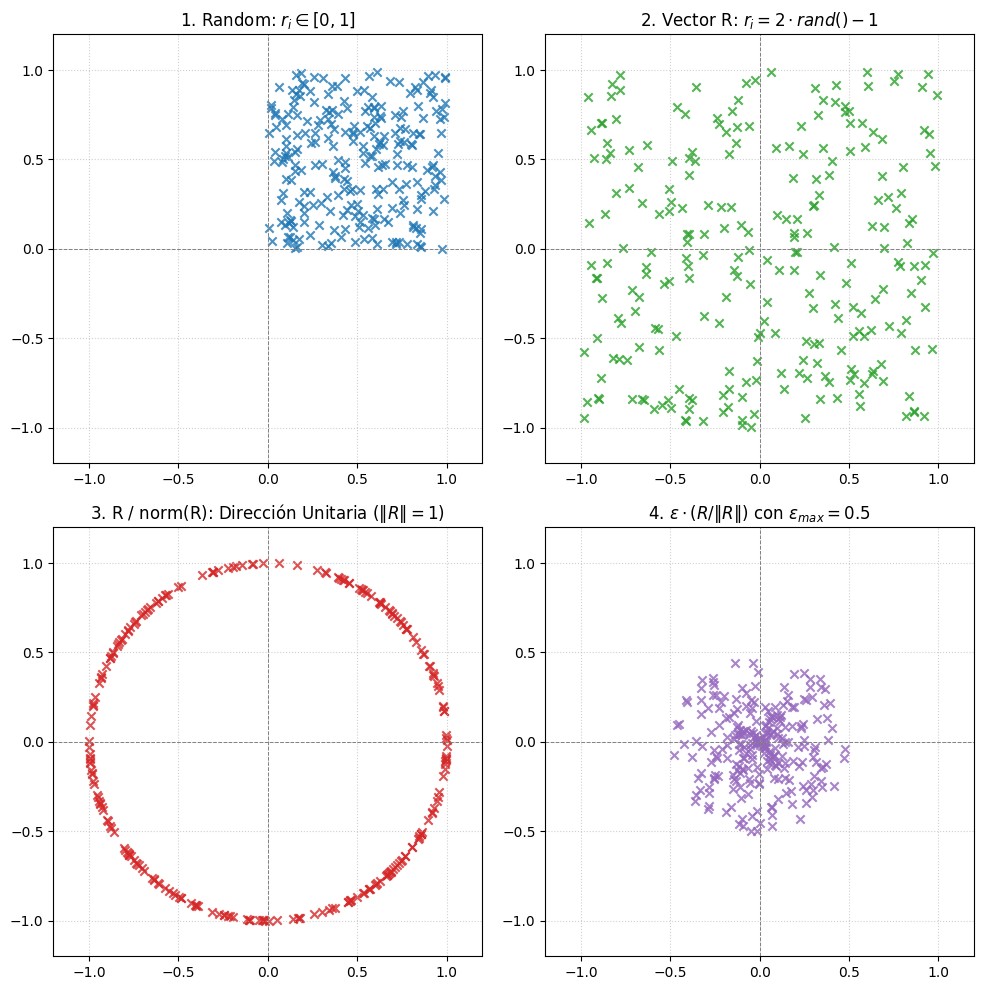

In [20]:
import random
import math
import matplotlib.pyplot as plt

# Cantidad de muestras a graficar
N = 250
max_eps = 0.5

# 1. Random puro: r_i = rand() en [0, 1]
puntos_random = [(random.random(), random.random()) for _ in range(N)]

# 2. Vector R centrado: r_i = 2 * rand() - 1 en [-1, 1]
puntos_R = [(2 * random.random() - 1, 2 * random.random() - 1) for _ in range(N)]

# 3. R / norm(R): Vector de avance normalizado
puntos_R_norm = []
for r1, r2 in puntos_R:
    norm = math.sqrt(r1**2 + r2**2)
    if norm > 0:
        puntos_R_norm.append((r1 / norm, r2 / norm))
    else:
        puntos_R_norm.append((0.0, 0.0))

# 4. E = random * E_max aplicado a la dirección unitaria
puntos_E = []
for u1, u2 in puntos_R_norm:
    eps = random.uniform(0, max_eps)
    puntos_E.append((eps * u1, eps * u2))

# ==========================================
# Configuración visual de las gráficas
# ==========================================
fig, axs = plt.subplots(2, 2, figsize=(10, 10))

# Gráfico 1: Random puro [0, 1] x [0, 1]
x1, y1 = zip(*puntos_random)
axs[0, 0].scatter(x1, y1, marker="x", color="tab:blue", alpha=0.8)
axs[0, 0].set_title(r"1. Random: $r_i \in [0, 1]$")
axs[0, 0].set_xlim(-1.2, 1.2)
axs[0, 0].set_ylim(-1.2, 1.2)
axs[0, 0].axhline(0, color="gray", linestyle="--", linewidth=0.7)
axs[0, 0].axvline(0, color="gray", linestyle="--", linewidth=0.7)
axs[0, 0].grid(True, linestyle=":", alpha=0.6)
axs[0, 0].set_aspect('equal')

# Gráfico 2: Vector R centrado [-1, 1] x [-1, 1]
x2, y2 = zip(*puntos_R)
axs[0, 1].scatter(x2, y2, marker="x", color="tab:green", alpha=0.8)
axs[0, 1].set_title(r"2. Vector R: $r_i = 2 \cdot rand() - 1$")
axs[0, 1].set_xlim(-1.2, 1.2)
axs[0, 1].set_ylim(-1.2, 1.2)
axs[0, 1].axhline(0, color="gray", linestyle="--", linewidth=0.7)
axs[0, 1].axvline(0, color="gray", linestyle="--", linewidth=0.7)
axs[0, 1].grid(True, linestyle=":", alpha=0.6)
axs[0, 1].set_aspect('equal')

# Gráfico 3: R / norm(R) (Esfera / Circunferencia Unitaria)
x3, y3 = zip(*puntos_R_norm)
axs[1, 0].scatter(x3, y3, marker="x", color="tab:red", alpha=0.8)
axs[1, 0].set_title(r"3. R / norm(R): Dirección Unitaria ($\|R\| = 1$)")
axs[1, 0].set_xlim(-1.2, 1.2)
axs[1, 0].set_ylim(-1.2, 1.2)
axs[1, 0].axhline(0, color="gray", linestyle="--", linewidth=0.7)
axs[1, 0].axvline(0, color="gray", linestyle="--", linewidth=0.7)
axs[1, 0].grid(True, linestyle=":", alpha=0.6)
axs[1, 0].set_aspect('equal')

# Gráfico 4: E = random * E_max (Círculo de radio max_eps)
x4, y4 = zip(*puntos_E)
axs[1, 1].scatter(x4, y4, marker="x", color="tab:purple", alpha=0.8)
axs[1, 1].set_title(rf"4. $\epsilon \cdot (R / \|R\|)$ con $\epsilon_{{max}} = {max_eps}$")
axs[1, 1].set_xlim(-1.2, 1.2)
axs[1, 1].set_ylim(-1.2, 1.2)
axs[1, 1].axhline(0, color="gray", linestyle="--", linewidth=0.7)
axs[1, 1].axvline(0, color="gray", linestyle="--", linewidth=0.7)
axs[1, 1].grid(True, linestyle=":", alpha=0.6)
axs[1, 1].set_aspect('equal')

plt.tight_layout()
plt.show()